# Predicting Insurance Claim Filing

## Research Question
Will a policyholder file an auto insurance claim during the policy period?

## Problem Statement

Insurers need to estimate which policies are likely to produce a claim in order to price risk, set reserves and focus loss-prevention efforts. This project builds a binary classification model that predicts `claim_status` (1 = claim filed, 0 = no claim) from the policy's tenure, the policyholder's age and region, and the insured vehicle's attributes.

## Dataset

**Source:** *Insurance Claims Dataset* by Sergey Litvinenko (Kaggle), stored at `data/Claimsdata.csv`.

- **58,592 policies and 41 columns**, with no missing values.
- **Target:** `claim_status`, which is heavily imbalanced: 93.6% no claim (54,844) and 6.4% claim (3,748), a ratio of about 14.6 : 1.

| Group | Columns |
|---|---|
| Identifier | `policy_id` |
| Policy | `subscription_length` (policy tenure) |
| Policyholder | `customer_age`, `region_code`, `region_density` |
| Vehicle | `vehicle_age`, `model`, `segment`, `fuel_type`, `engine_type`, `max_torque`, `max_power`, `displacement`, `cylinder`, `transmission_type`, `steering_type`, `rear_brakes_type`, `turning_radius`, `length`, `width`, `gross_weight`, `airbags`, `ncap_rating` |
| Vehicle safety and comfort flags (Yes/No) | 17 `is_*` columns, such as `is_esc`, `is_tpms`, `is_parking_camera`, `is_brake_assist`, `is_speed_alert` |

The dataset does **not** contain gender, occupation, credit score, premium, deductible or prior-claim history, so those factors are outside the scope of this analysis.

## Import Libraries and Load data

In [44]:
# Import necessary libraries

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

In [45]:
# Load insurance claims data
data = pd.read_csv('data/Claimsdata.csv')

## Initial Data Inspection

1. Preview the first and last rows.
2. Review column types and summary statistics.
3. Check for missing values and confirm the dataset shape.
4. Examine the distribution of the target variable `claim_status`.

In [46]:
# Preview the first rows of the claims data
data.head()

,policy_id,subscription_length,vehicle_age,customer_age,region_code,region_density,segment,model,fuel_type,max_torque,...,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,claim_status
0,POL045360,9.3,1.2,41,C8,8794,C2,M4,Diesel,250Nm@2750rpm,...,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,3,0
1,POL016745,8.2,1.8,35,C2,27003,C1,M9,Diesel,200Nm@1750rpm,...,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,4,0
2,POL007194,9.5,0.2,44,C8,8794,C2,M4,Diesel,250Nm@2750rpm,...,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,3,0
3,POL018146,5.2,0.4,44,C10,73430,A,M1,CNG,60Nm@3500rpm,...,No,No,No,Yes,No,No,No,Yes,0,0
4,POL049011,10.1,1.0,56,C13,5410,B2,M5,Diesel,200Nm@3000rpm,...,No,Yes,Yes,Yes,No,No,Yes,Yes,5,0


In [47]:
# Preview the last rows of the claims data
data.tail()

,policy_id,subscription_length,vehicle_age,customer_age,region_code,region_density,segment,model,fuel_type,max_torque,...,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,claim_status
58587,POL019269,10.6,2.6,48,C5,34738,B2,M6,Petrol,113Nm@4400rpm,...,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0
58588,POL001254,2.3,2.2,37,C3,4076,C2,M4,Diesel,250Nm@2750rpm,...,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,3,0
58589,POL019859,6.6,2.2,35,C8,8794,B2,M6,Petrol,113Nm@4400rpm,...,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0
58590,POL014061,4.1,3.6,44,C8,8794,B2,M6,Petrol,113Nm@4400rpm,...,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0
58591,POL054184,3.1,0.4,49,C12,34791,B2,M6,Petrol,113Nm@4400rpm,...,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0


In [48]:
# Column types and non-null counts
data.info()

# Statistical summary of the numeric columns
data.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58592 entries, 0 to 58591
Data columns (total 41 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   policy_id                         58592 non-null  object 
 1   subscription_length               58592 non-null  float64
 2   vehicle_age                       58592 non-null  float64
 3   customer_age                      58592 non-null  int64  
 4   region_code                       58592 non-null  object 
 5   region_density                    58592 non-null  int64  
 6   segment                           58592 non-null  object 
 7   model                             58592 non-null  object 
 8   fuel_type                         58592 non-null  object 
 9   max_torque                        58592 non-null  object 
 10  max_power                         58592 non-null  object 
 11  engine_type                       58592 non-null  object 
 12  airb

,subscription_length,vehicle_age,customer_age,region_density,airbags,displacement,cylinder,turning_radius,length,width,gross_weight,ncap_rating,claim_status
count,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000
mean,6.111688,1.388473,44.823935,18826.858667,3.137066,1162.355851,3.626963,4.852893,3850.476891,1672.233667,1385.276813,1.759950,0.063968
std,4.142790,1.134413,6.935604,17660.174792,1.832641,266.304786,0.483616,0.228061,311.457119,112.089135,212.423085,1.389576,0.244698
min,0.000000,0.000000,35.000000,290.000000,1.000000,796.000000,3.000000,4.500000,3445.000000,1475.000000,1051.000000,0.000000,0.000000
25%,2.100000,0.400000,39.000000,6112.000000,2.000000,796.000000,3.000000,4.600000,3445.000000,1515.000000,1185.000000,0.000000,0.000000
50%,5.700000,1.200000,44.000000,8794.000000,2.000000,1197.000000,4.000000,4.800000,3845.000000,1735.000000,1335.000000,2.000000,0.000000
75%,10.400000,2.200000,49.000000,27003.000000,6.000000,1493.000000,4.000000,5.000000,3995.000000,1755.000000,1510.000000,3.000000,0.000000
max,14.000000,20.000000,75.000000,73430.000000,6.000000,1498.000000,4.000000,5.200000,4300.000000,1811.000000,1720.000000,5.000000,1.000000


In [49]:
# Missing values per column
print(data.isna().sum())

# Number of rows and columns
print(data.shape)

policy_id                           0
subscription_length                 0
vehicle_age                         0
customer_age                        0
region_code                         0
region_density                      0
segment                             0
model                               0
fuel_type                           0
max_torque                          0
max_power                           0
engine_type                         0
airbags                             0
is_esc                              0
is_adjustable_steering              0
is_tpms                             0
is_parking_sensors                  0
is_parking_camera                   0
rear_brakes_type                    0
displacement                        0
cylinder                            0
transmission_type                   0
steering_type                       0
turning_radius                      0
length                              0
width                               0
gross_weight

### Target Variable Distribution (Class Imbalance)

Check how `claim_status` is split between policies with no claim (0) and policies with a claim (1).

              count  percent
claim_status                
0             54844     93.6
1              3748      6.4
Imbalance ratio (No Claim : Claim) = 14.6 : 1


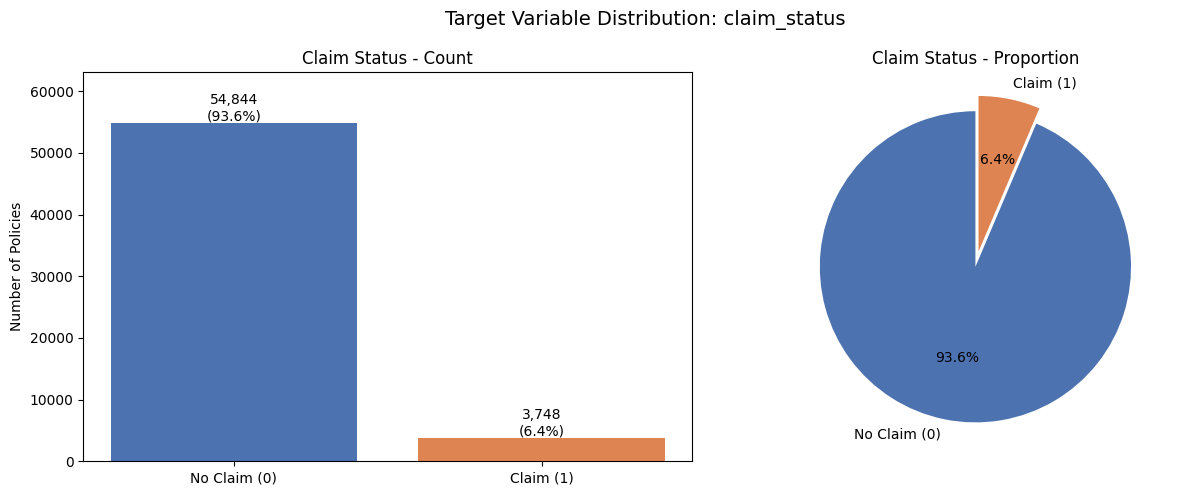

In [50]:
counts = data['claim_status'].value_counts().sort_index()
pcts = data['claim_status'].value_counts(normalize=True).sort_index() * 100
labels = ['No Claim (0)', 'Claim (1)']
colors = ['#4C72B0', '#DD8452']

print(pd.DataFrame({'count': counts, 'percent': pcts.round(2)}))
print(f"Imbalance ratio (No Claim : Claim) = {counts[0] / counts[1]:.1f} : 1")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

bars = axes[0].bar(labels, counts.values, color=colors)
for bar, c, p in zip(bars, counts.values, pcts.values):
    axes[0].annotate(f'{c:,}\n({p:.1f}%)', (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                     ha='center', va='bottom')
axes[0].set_title('Claim Status - Count')
axes[0].set_ylabel('Number of Policies')
axes[0].set_ylim(0, counts.max() * 1.15)

axes[1].pie(counts.values, labels=labels, colors=colors, autopct='%1.1f%%',
            startangle=90, explode=(0, 0.1))
axes[1].set_title('Claim Status - Proportion')

plt.suptitle('Target Variable Distribution: claim_status', fontsize=14)
plt.tight_layout()
plt.show()

**Observation:** The dataset is highly imbalanced. Only **6.4%** of policies (3,748) have a claim, compared with **93.6%** (54,844) with no claim, a ratio of about **14.6 : 1**.

**Implications for modeling:**
- Accuracy is misleading here, because a model that always predicts "No Claim" scores 93.6%. Evaluate with **recall, precision, F1, PR-AUC and ROC-AUC** instead.
- Use a **stratified** train/test split and stratified cross-validation so both sets keep the same claim rate.
- Handle the imbalance with `class_weight='balanced'` or by resampling the training data only (SMOTE, under-sampling).
- Tune the classification threshold rather than using the default of 0.5.

## Step 1: Explore Categorical Features

Review the values of each categorical column, then check how much of the vehicle information is already captured by `model`.

In [51]:
for col in ['segment', 'model', 'fuel_type', 'region_code', 'engine_type',
            'steering_type', 'transmission_type', 'rear_brakes_type']:
    print(f"--- {col} ({data[col].nunique()} unique) ---")
    print(data[col].value_counts().to_string(), '\n')

--- segment (6 unique) ---
segment
B2         18314
A          17321
C2         14018
B1          4173
C1          3557
Utility     1209 

--- model (11 unique) ---
model
M1     14948
M4     14018
M6     13776
M8      4173
M7      2940
M3      2373
M9      2114
M5      1598
M10     1209
M2      1080
M11      363 

--- fuel_type (3 unique) ---
fuel_type
Petrol    20532
CNG       20330
Diesel    17730 

--- region_code (22 unique) ---
region_code
C8     13654
C2      7342
C5      6979
C3      6101
C14     3660
C13     3423
C10     3155
C9      2734
C7      2167
C12     1589
C1      1468
C11     1212
C19      952
C6       890
C15      771
C4       665
C17      492
C16      401
C21      379
C18      242
C22      207
C20      109 

--- engine_type (11 unique) ---
engine_type
F8D Petrol Engine            14948
1.5 L U2 CRDi                14018
K Series Dual jet            13776
K10C                          4173
1.2 L K Series Engine         2940
1.0 SCe                       2373
i-DTEC   

In [52]:
policy_cols = ['policy_id', 'subscription_length', 'vehicle_age', 'customer_age',
               'region_code', 'region_density', 'claim_status']
vehicle_cols = [c for c in data.columns if c not in policy_cols + ['model']]

max_unique_within_model = data.groupby('model')[vehicle_cols].nunique().max()
print(f"Vehicle columns with a single value per model: {(max_unique_within_model == 1).sum()} of {len(vehicle_cols)}")
print("region_code -> region_density is one-to-one:",
      (data.groupby('region_code')['region_density'].nunique() == 1).all())

Vehicle columns with a single value per model: 33 of 33
region_code -> region_density is one-to-one: True


**Observation:** All 33 vehicle columns (specs and safety features) have exactly one value per `model`, and `region_code` maps one-to-one to `region_density`. The dataset therefore contains only five independent sources of information: `subscription_length`, `vehicle_age`, `customer_age`, region and `model`. Keeping every vehicle column would add heavy multicollinearity without adding information.

## Step 2: Univariate Analysis of Numeric Features

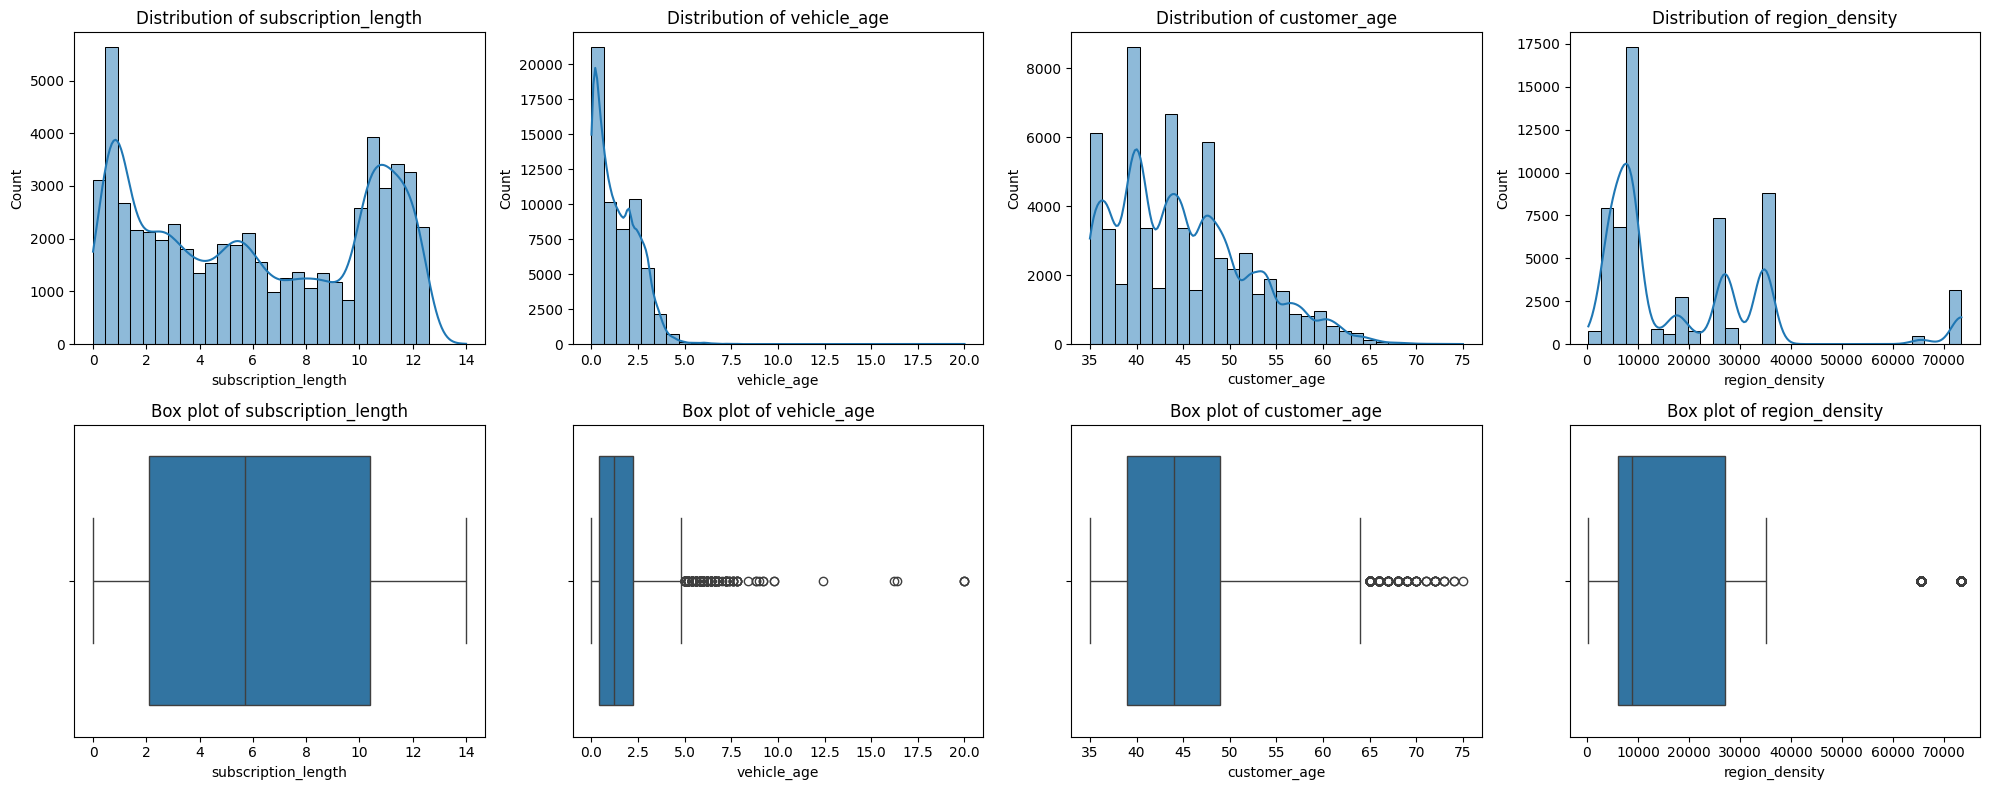

Skewness:
 subscription_length    0.05
vehicle_age            1.09
customer_age           0.66
region_density         1.67
dtype: float64 

vehicle_age 99th percentile = 4.2, rows above it = 572


In [53]:
num_cols = ['subscription_length', 'vehicle_age', 'customer_age', 'region_density']

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for i, col in enumerate(num_cols):
    sns.histplot(data[col], bins=30, kde=True, ax=axes[0, i])
    axes[0, i].set_title(f'Distribution of {col}')
    sns.boxplot(x=data[col], ax=axes[1, i])
    axes[1, i].set_title(f'Box plot of {col}')
plt.tight_layout()
plt.show()

print("Skewness:\n", data[num_cols].skew().round(2), '\n')
q99 = data['vehicle_age'].quantile(0.99)
print(f"vehicle_age 99th percentile = {q99}, rows above it = {(data['vehicle_age'] > q99).sum()}")

**Observations:**
- `subscription_length` is bimodal, with peaks near 1 year and near 11 years, and is not skewed (skew 0.05).
- `vehicle_age` is right-skewed (skew 1.09). Most vehicles are under 5 years old, but 572 rows exceed the 99th percentile (4.2), with a maximum of 20. These will be capped.
- `customer_age` starts at 35 and is mildly right-skewed (skew 0.66).
- `region_density` takes only 22 distinct values, one per region, so it behaves like a categorical feature.

## Step 3: Bivariate Analysis - Features vs. `claim_status`

### 3a. Numeric features by claim status
KDE curves are normalized within each class (`common_norm=False`) so that the small claim class is visible.

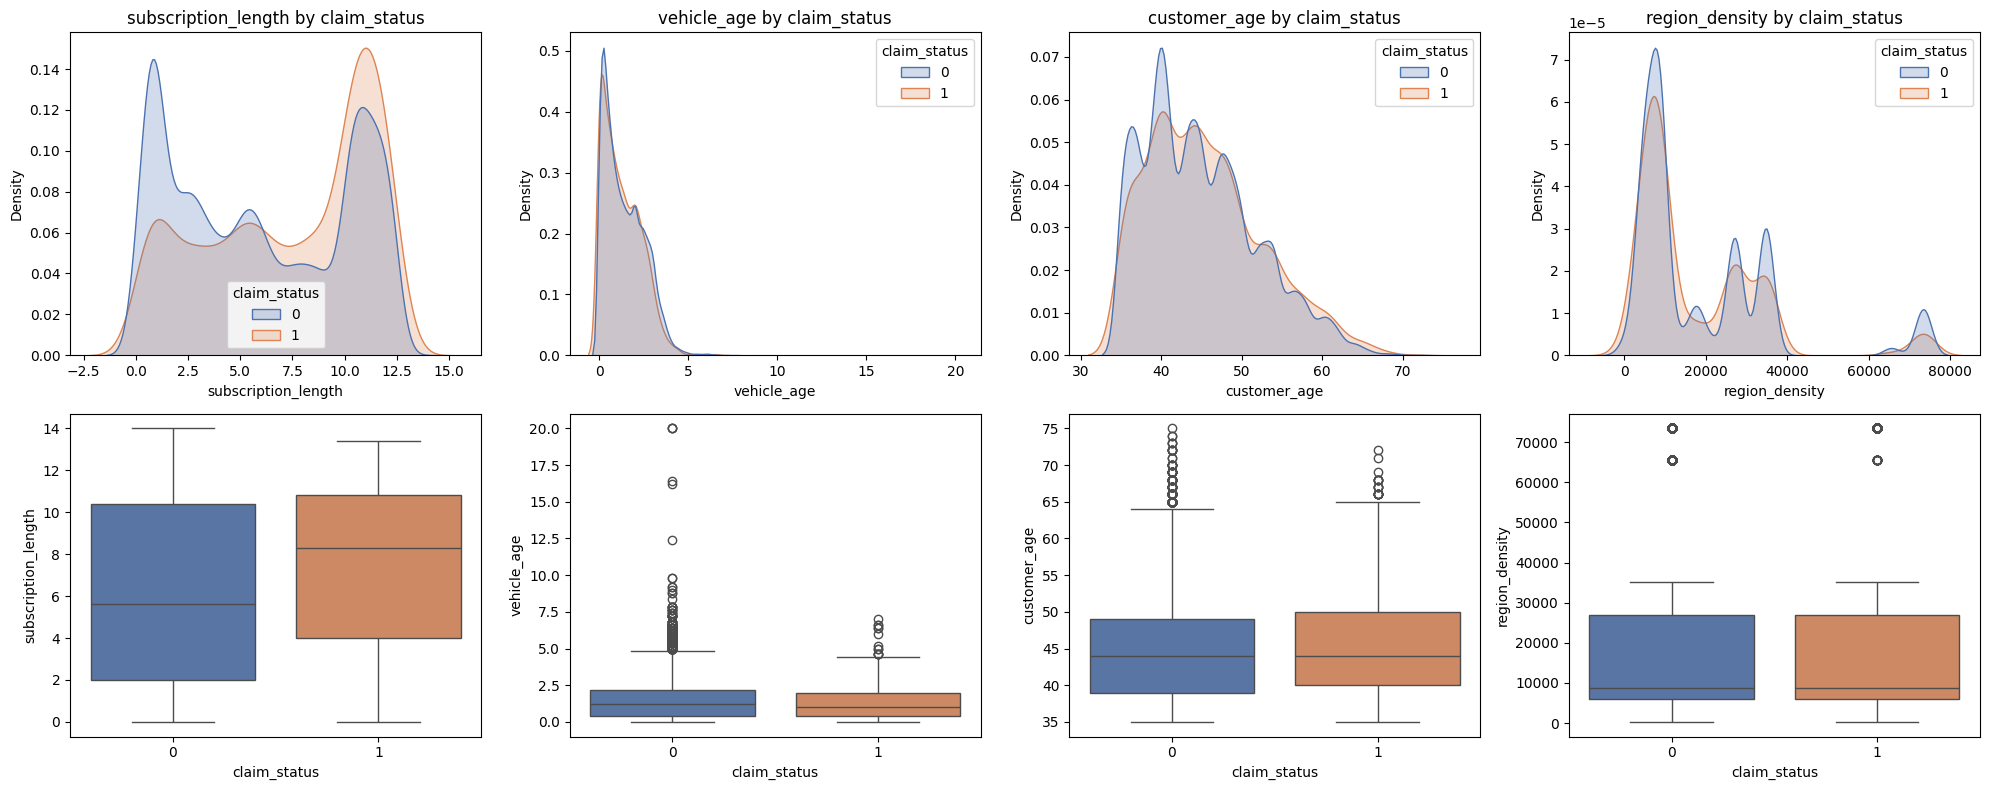

subscription_length        vehicle_age        customer_age  \
                            mean median        mean median         mean   
claim_status                                                              
0                           6.03    5.6        1.40    1.2        44.78   
1                           7.36    8.3        1.27    1.0        45.41   

                    region_density          
             median           mean  median  
claim_status                                
0              44.0       18909.07  8794.0  
1              44.0       17623.82  8794.0

In [54]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for i, col in enumerate(num_cols):
    sns.kdeplot(data=data, x=col, hue='claim_status', common_norm=False, fill=True,
                palette=colors, ax=axes[0, i])
    axes[0, i].set_title(f'{col} by claim_status')
    sns.boxplot(data=data, x='claim_status', y=col, hue='claim_status', palette=colors,
                legend=False, ax=axes[1, i])
plt.tight_layout()
plt.show()

data.groupby('claim_status')[num_cols].agg(['mean', 'median']).round(2)

**Observations:**
- `subscription_length` shows the clearest separation. Policies with claims have a median tenure of 8.3 compared with 5.6 for policies without claims, and the claim class is concentrated around 10–12.
- Policies with claims have slightly newer vehicles (median `vehicle_age` 1.0 vs 1.2).
- `customer_age` and `region_density` look almost identical across the two classes.

### 3b. Claim rate by category
Claim **rate** (share of policies with a claim) is plotted instead of counts because of the imbalance. The red dashed line is the overall claim rate. Age, vehicle age and tenure are binned for this view only.

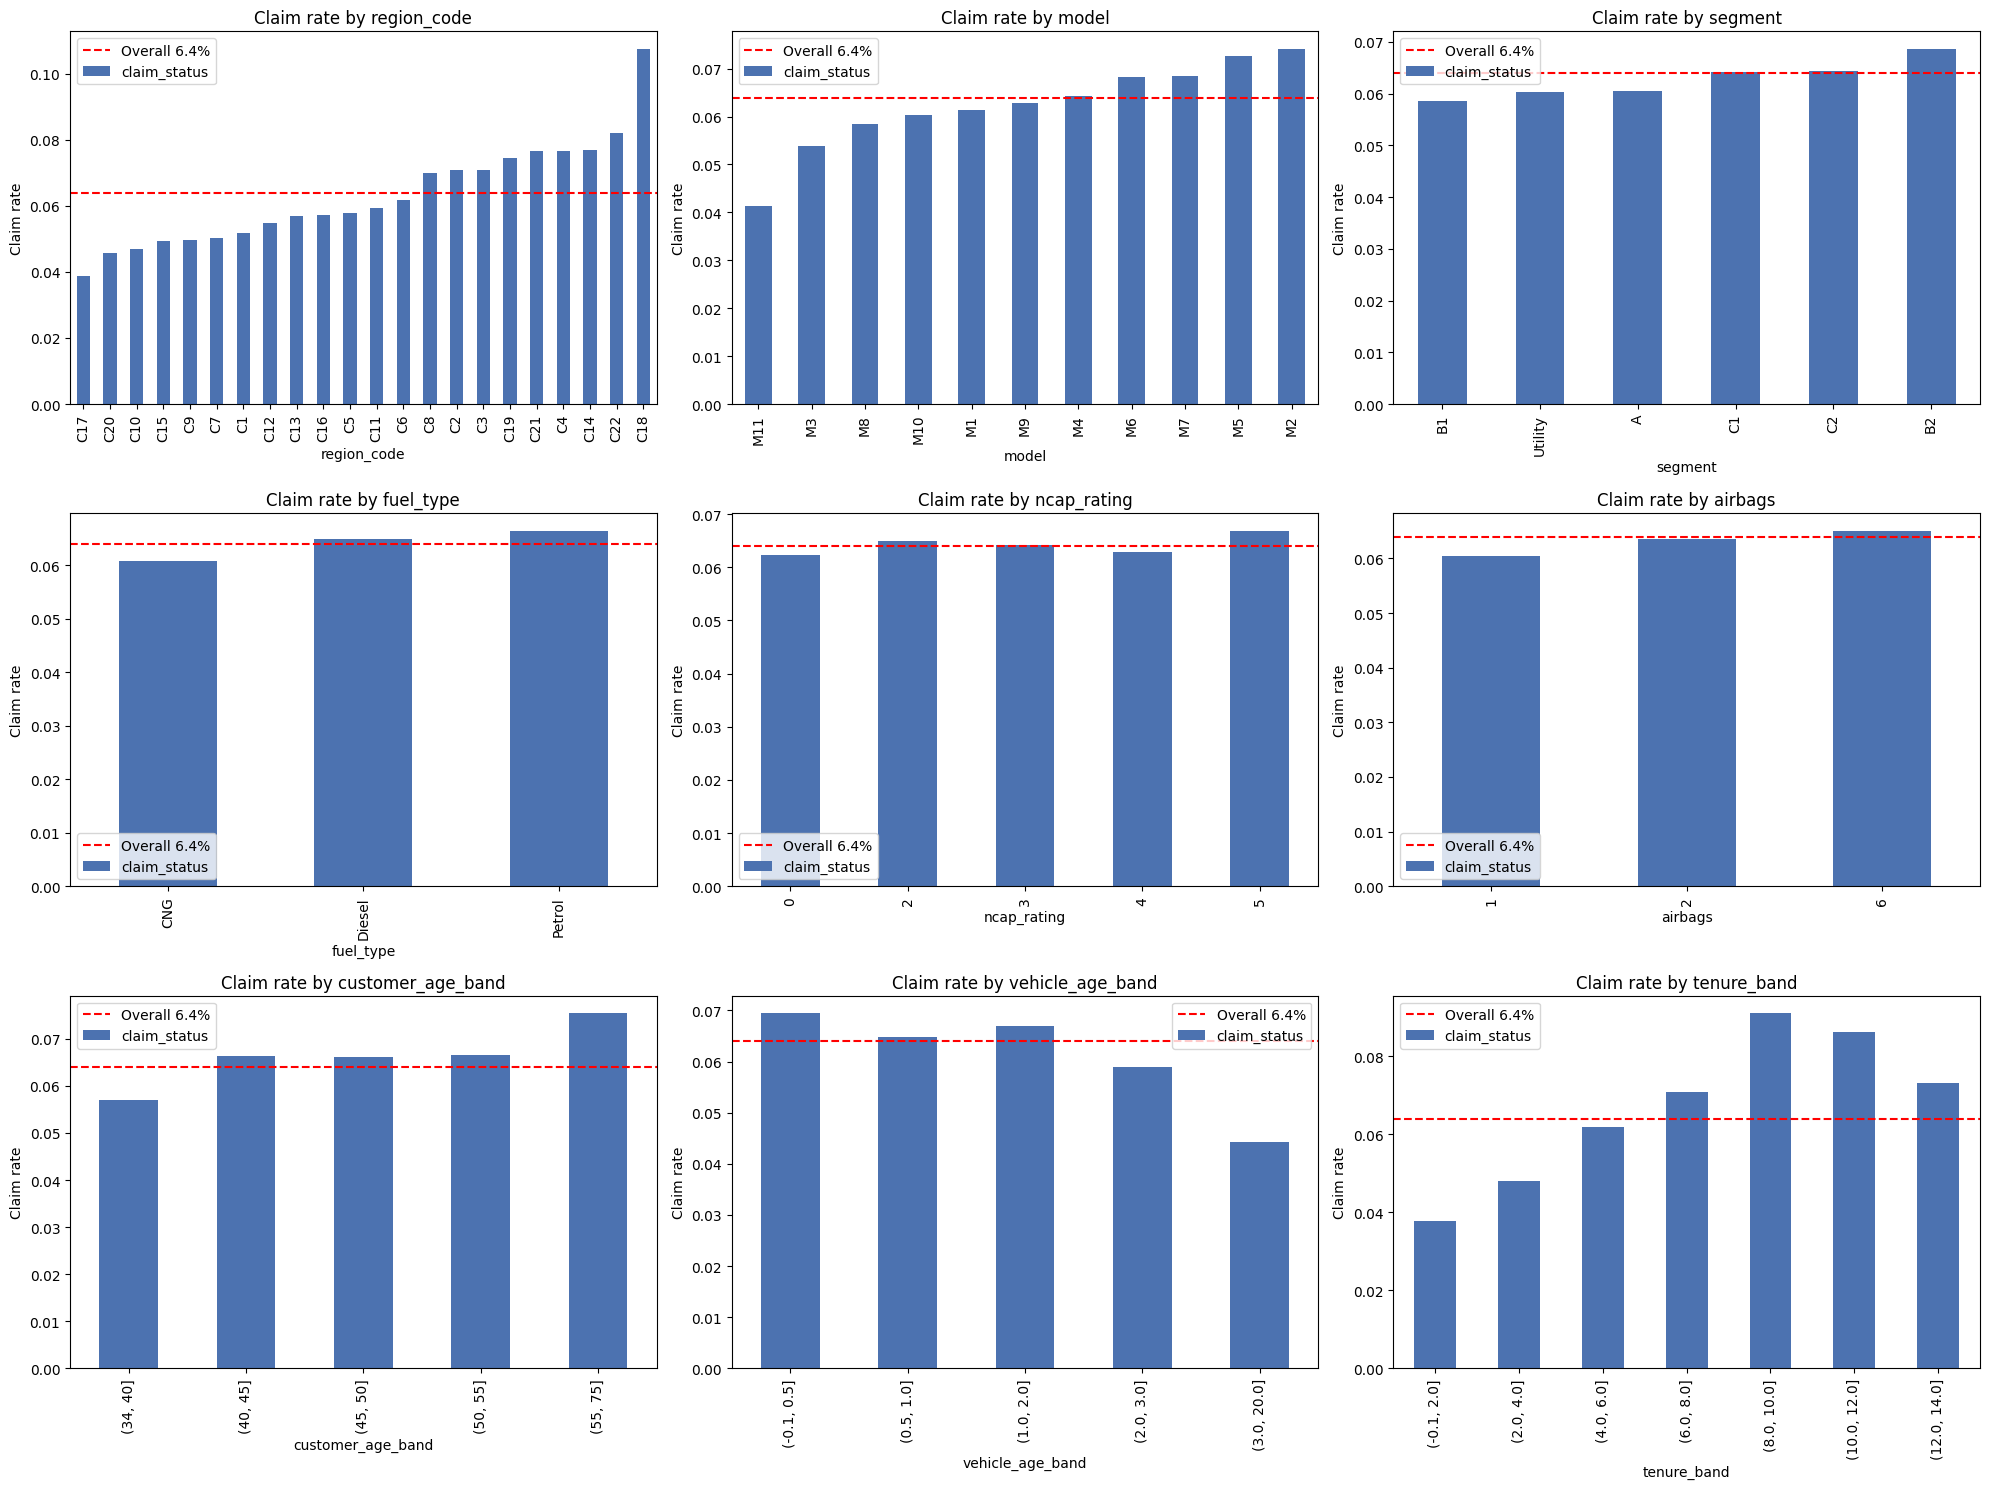

,policies,claim_rate
tenure_band,,
"(-0.1, 2.0]",14437,0.038
"(2.0, 4.0]",8352,0.048
"(4.0, 6.0]",7795,0.062
"(6.0, 8.0]",5447,0.071
"(8.0, 10.0]",5087,0.091
"(10.0, 12.0]",14587,0.086
"(12.0, 14.0]",2887,0.073


In [55]:
eda = data.copy()
eda['customer_age_band'] = pd.cut(eda['customer_age'], [34, 40, 45, 50, 55, 75])
eda['vehicle_age_band'] = pd.cut(eda['vehicle_age'], [-0.1, 0.5, 1, 2, 3, 20])
eda['tenure_band'] = pd.cut(eda['subscription_length'], [-0.1, 2, 4, 6, 8, 10, 12, 14])

overall_rate = eda['claim_status'].mean()
rate_cols = ['region_code', 'model', 'segment', 'fuel_type', 'ncap_rating', 'airbags',
             'customer_age_band', 'vehicle_age_band', 'tenure_band']
unordered = ['region_code', 'model', 'segment', 'fuel_type']

fig, axes = plt.subplots(3, 3, figsize=(20, 15))
for ax, col in zip(axes.ravel(), rate_cols):
    rates = eda.groupby(col, observed=True)['claim_status'].mean()
    if col in unordered:
        rates = rates.sort_values()
    rates.plot.bar(ax=ax, color=colors[0])
    ax.axhline(overall_rate, color='red', ls='--', label=f'Overall {overall_rate:.1%}')
    ax.set_title(f'Claim rate by {col}')
    ax.set_ylabel('Claim rate')
    ax.legend()
plt.tight_layout()
plt.show()

eda.groupby('tenure_band', observed=True)['claim_status'].agg(policies='size', claim_rate='mean').round(3)

**Observations:**
- **Tenure** has the strongest pattern. The claim rate rises from 3.8% for tenure of 2 or less to 9.1% for tenure of 8–10, then eases slightly. This non-linear shape suggests tree models or a binned or spline feature could help.
- **Region** varies widely, from about 3.9% (C17) to about 10.8% (C18). This is useful signal, although some regions have few policies.
- **Model** ranges from 4.1% (M11) to 7.4% (M2), a modest effect.
- `segment`, `fuel_type`, `ncap_rating` and `airbags` stay within about one percentage point of the 6.4% average, so they carry weak signal.
- **Customer age:** the 55+ group is the highest at 7.5% and the 35–40 group is the lowest at 5.7%.
- **Vehicle age:** vehicles older than 3 years have a lower claim rate of 4.4%.

## Step 4: Correlation and Redundancy

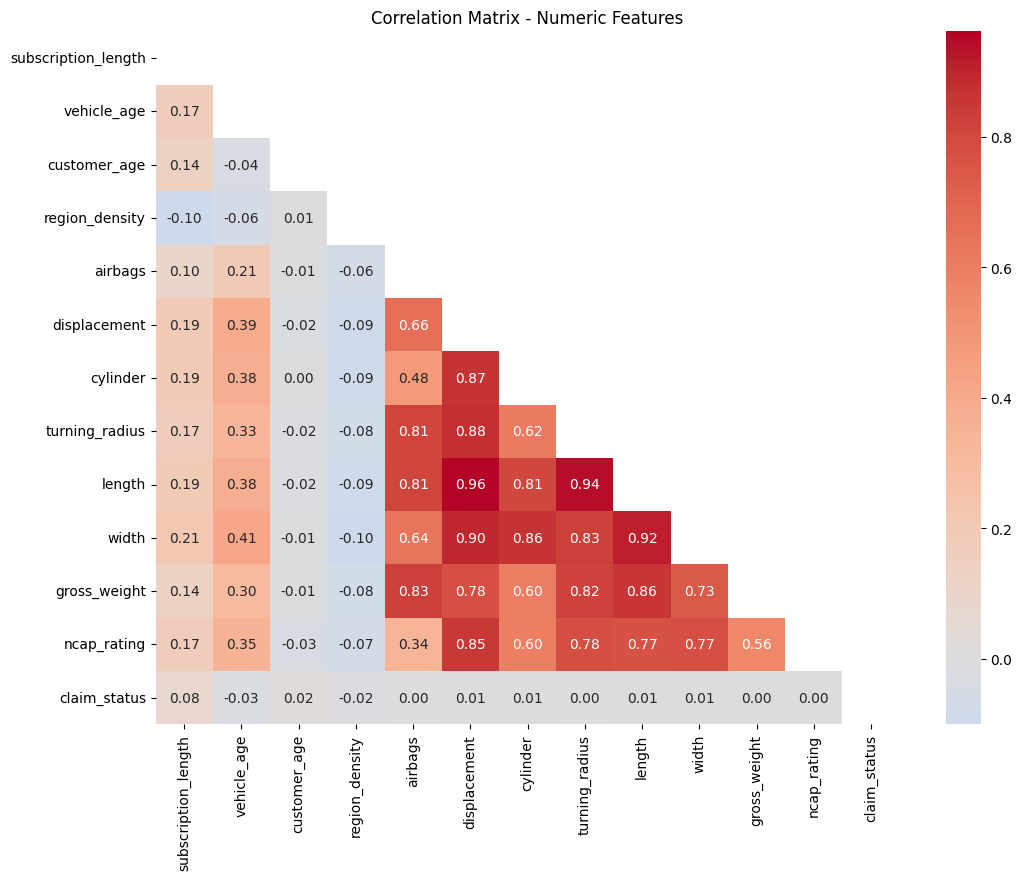

Highly correlated pairs (|r| > 0.8):
displacement    length            0.96
turning_radius  length            0.94
length          width             0.92
displacement    width             0.90
                turning_radius    0.88
                cylinder          0.87
cylinder        width             0.86
length          gross_weight      0.86
displacement    ncap_rating       0.85
airbags         gross_weight      0.83
turning_radius  width             0.83
                gross_weight      0.82
airbags         turning_radius    0.81
                length            0.81
cylinder        length            0.81

Correlation with claim_status:
subscription_length    0.079
vehicle_age           -0.028
customer_age           0.022
region_density        -0.018
cylinder               0.013
width                  0.010
displacement           0.008
length                 0.006
gross_weight           0.004
ncap_rating            0.004
airbags                0.003
turning_radius         0.00

In [56]:
corr = data.select_dtypes('number').corr()
upper = np.triu(np.ones(corr.shape, dtype=bool))

plt.figure(figsize=(12, 9))
sns.heatmap(corr, mask=upper, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix - Numeric Features')
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print("Highly correlated pairs (|r| > 0.8):")
print(pairs[pairs.abs() > 0.8].sort_values(key=abs, ascending=False).round(2).to_string())
print("\nCorrelation with claim_status:")
print(corr['claim_status'].drop('claim_status').sort_values(key=abs, ascending=False).round(3).to_string())

**Observations:**
- The vehicle size and engine columns (`length`, `width`, `displacement`, `turning_radius`, `cylinder`, `gross_weight`, `airbags`, `ncap_rating`) are highly correlated with one another (r = 0.81–0.96), which confirms they are redundant.
- Every linear correlation with `claim_status` is weak. `subscription_length` is the highest at 0.079, and all vehicle columns are 0.013 or below. Expect only modest predictive power, and consider non-linear models.

## Step 5: Feature Engineering and Feature Selection

- Convert the `is_*` Yes/No columns to 1/0.
- Parse `max_torque` and `max_power` into numeric values, then create `power_to_weight`.
- Combine the safety columns, `airbags` and `ncap_rating` into a single `safety_score`.
- Cap `vehicle_age` at the 99th percentile.
- Drop `policy_id` (an identifier), `region_density` (duplicates `region_code`), `model` and the raw vehicle columns (all determined by `model`). Keep a small set of interpretable vehicle features instead.

In [57]:
df = data.copy()

yn_cols = [c for c in df.columns if c.startswith('is_')]
df[yn_cols] = (df[yn_cols] == 'Yes').astype(int)

df[['torque_nm', 'torque_rpm']] = df['max_torque'].str.extract(r'([\d.]+)Nm@([\d.]+)rpm').astype(float)
df[['power_bhp', 'power_rpm']] = df['max_power'].str.extract(r'([\d.]+)bhp@([\d.]+)rpm').astype(float)
df['power_to_weight'] = df['power_bhp'] / df['gross_weight']

safety_cols = ['is_esc', 'is_tpms', 'is_brake_assist', 'is_parking_sensors',
               'is_parking_camera', 'is_speed_alert', 'is_ecw']
df['safety_score'] = df[safety_cols].sum(axis=1) + df['airbags'] + df['ncap_rating']

df['vehicle_age'] = df['vehicle_age'].clip(upper=df['vehicle_age'].quantile(0.99))

num_features = ['subscription_length', 'vehicle_age', 'customer_age', 'safety_score', 'power_to_weight']
cat_features = ['region_code', 'segment', 'fuel_type', 'transmission_type']
target = 'claim_status'

df_model = df[num_features + cat_features + [target]]
print(f"Columns reduced from {data.shape[1]} to {df_model.shape[1]}")
df_model.head()

Columns reduced from 41 to 10


,subscription_length,vehicle_age,customer_age,safety_score,power_to_weight,region_code,segment,fuel_type,transmission_type,claim_status
0,9.3,1.2,41,16,0.065959,C8,C2,Diesel,Automatic,0
1,8.2,1.8,35,10,0.093140,C2,C1,Diesel,Manual,0
2,9.5,0.2,44,16,0.065959,C8,C2,Diesel,Automatic,0
3,5.2,0.4,44,4,0.034059,C10,A,CNG,Manual,0
4,10.1,1.0,56,10,0.059577,C13,B2,Diesel,Manual,0


## Step 6: Feature Importance Screening

Mutual information and a shallow Random Forest give a quick, model-independent ranking of the selected features. Categorical features are label-encoded for this screening only.

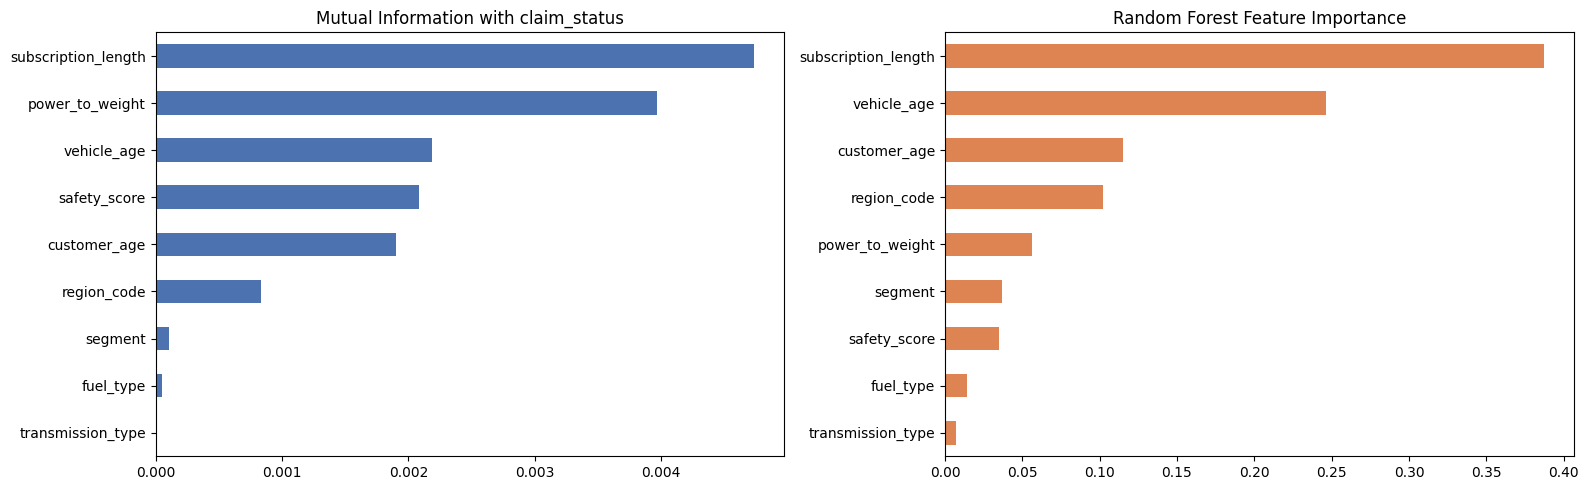

In [58]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier

X_screen = df_model[num_features + cat_features].copy()
for c in cat_features:
    X_screen[c] = X_screen[c].astype('category').cat.codes
y_screen = df_model[target]

discrete_mask = [c in cat_features for c in X_screen.columns]
mi = pd.Series(mutual_info_classif(X_screen, y_screen, discrete_features=discrete_mask, random_state=42),
               index=X_screen.columns).sort_values()

rf = RandomForestClassifier(n_estimators=200, max_depth=8, class_weight='balanced',
                            random_state=42, n_jobs=-1).fit(X_screen, y_screen)
rf_imp = pd.Series(rf.feature_importances_, index=X_screen.columns).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
mi.plot.barh(ax=axes[0], color=colors[0], title='Mutual Information with claim_status')
rf_imp.plot.barh(ax=axes[1], color=colors[1], title='Random Forest Feature Importance')
plt.tight_layout()
plt.show()

**Observations:** Both methods rank `subscription_length` first. The Random Forest ranks `vehicle_age`, `customer_age` and `region_code` next, while mutual information also scores `power_to_weight` highly. `fuel_type` and `transmission_type` add little in either ranking and could be dropped in later iterations.

## Step 7: Train/Test Split and Preprocessing Pipeline

- Use a stratified 80/20 split so both sets keep the 6.4% claim rate.
- Scale the numeric features and one-hot encode the categorical features inside a `ColumnTransformer`, so the transformation is learned from the training data only.

In [59]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

X = df_model[num_features + cat_features]
y = df_model[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features),
])

print(f"Train: {X_train.shape}, claim rate = {y_train.mean():.3%}")
print(f"Test:  {X_test.shape}, claim rate = {y_test.mean():.3%}")

Train: (46873, 9), claim rate = 6.396%
Test:  (11719, 9), claim rate = 6.400%


## Step 8: Baseline Models

- A `DummyClassifier` that always predicts "No Claim" shows why accuracy is misleading.
- Logistic regression with `class_weight='balanced'` is the first real baseline.
- Metrics: accuracy, precision, recall, F1, ROC-AUC and PR-AUC. For PR-AUC, a random model scores about 0.064, the claim rate.

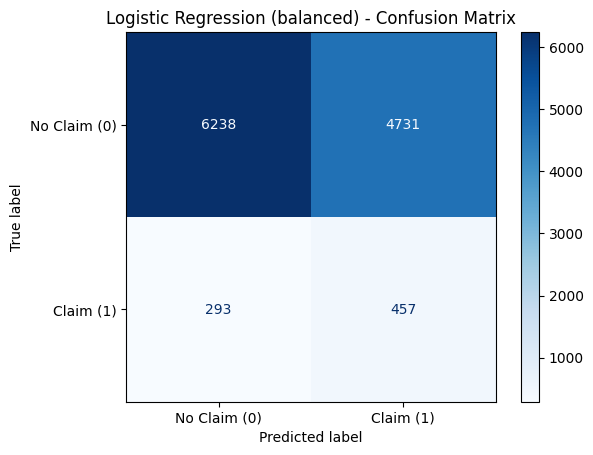

,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,
Dummy (most frequent),0.936,0.000,0.000,0.000,0.500,0.064
Logistic Regression (balanced),0.571,0.088,0.609,0.154,0.625,0.095


In [60]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, ConfusionMatrixDisplay)

models = {
    'Dummy (most frequent)': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression (balanced)': LogisticRegression(class_weight='balanced', max_iter=1000),
}

results, fitted = [], {}
for name, clf in models.items():
    pipe = Pipeline([('prep', clone(preprocessor)), ('clf', clf)]).fit(X_train, y_train)
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    fitted[name] = pipe
    results.append({
        'model': name,
        'accuracy': accuracy_score(y_test, pred),
        'precision': precision_score(y_test, pred, zero_division=0),
        'recall': recall_score(y_test, pred),
        'f1': f1_score(y_test, pred),
        'roc_auc': roc_auc_score(y_test, proba),
        'pr_auc': average_precision_score(y_test, proba),
    })

ConfusionMatrixDisplay.from_estimator(fitted['Logistic Regression (balanced)'], X_test, y_test,
                                      display_labels=labels, cmap='Blues')
plt.title('Logistic Regression (balanced) - Confusion Matrix')
plt.show()

pd.DataFrame(results).set_index('model').round(3)

**Observations:**
- The dummy model reaches **93.6% accuracy** but finds no claims (recall 0), which confirms accuracy is the wrong metric.
- Balanced logistic regression catches **61% of claims** (recall 0.609), with ROC-AUC 0.625 and PR-AUC 0.095, compared with a random baseline of 0.064. Precision is low (8.8%), so many policies without claims are flagged.

**Next steps:** tune regularization (C, L1/L2), try tree ensembles (Random Forest, Gradient Boosting) to capture the non-linear tenure and region patterns, compare SMOTE with class weights, and tune the decision threshold for the best precision/recall trade-off.

## Summary of Key Findings

1. **The data is highly imbalanced.** A model that always predicts "No Claim" is 93.6% accurate but catches no claims.
2. **The vehicle features are largely redundant.** All 33 vehicle columns have exactly one value per `model`, and there are only 11 models. The size and engine columns are highly correlated (r = 0.81–0.96). In practice the data has only five independent sources of information: tenure, vehicle age, customer age, region and vehicle model.
3. **Policy tenure is the strongest predictor.** Claim rate rises from 3.8% for tenure of 2 or less to about 9% for tenure of 8–12. Median tenure is 8.3 for policies with a claim vs 5.6 for policies without. Tenure ranks first in both mutual information and Random Forest importance.
4. **Region matters.** Claim rates range from about 3.9% to about 10.8% across the 22 regions.
5. **Other factors have weak effects.** Policies with claims have slightly newer vehicles (median 1.0 vs 1.2 years), and older customers (55+) claim slightly more often. Vehicle model shifts the claim rate only between 4.1% and 7.4%. Segment, fuel type, NCAP rating and airbags stay close to the 6.4% average, and fuel type and transmission type rank lowest in feature importance.
6. **Linear signal is weak.** No numeric feature has an absolute correlation with `claim_status` above 0.08.
7. **Baseline model.** Balanced logistic regression finds about 61% of claims (recall 0.609), with ROC-AUC 0.625 and PR-AUC 0.095, compared with 0.064 for a random model. Precision is low (0.088), so the available features separate the two classes only modestly.